# 12 · Ein Layoutplan, zwei Ansichten (ENC und KEY)

**NHyDB-0.28.2-Notebook-Reihe · v1**

NHyDB hält das **Schema** – Realms, Shapes, Layouts, MATH-Formeln, Indizes – außerhalb der Datendatei, in einem verschlüsselten **Layoutplan** mit eigener **Schlüsseldatei**. Dieses Notebook zeigt den Plan zweimal: als verschlüsselte Datei auf der Platte und als autorisierte Ansicht einer geöffneten Datenbank. Danach greift es die Dateien auf acht verschiedene Arten an – und die Engine verweigert jedes Mal.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* welche drei Dateien zusammengehören und wie sie aneinander gebunden sind
* was die verschlüsselte Plandatei wirklich enthält – und was sie nicht verrät
* die *autorisierte Ansicht*: das vollständige Schema, gelesen über die API einer geöffneten Datenbank
* wie die Plangeneration jeder Schemaänderung folgt
* *fail closed*: Fehlende oder manipulierte Dateien werden erkannt, und das Öffnen wird verweigert
* die ehrlichen Grenzen: Die Datendatei selbst ist **nicht** verschlüsselt

**Vorher empfohlen:** [02](02_from_address_to_data_v1.ipynb) und [11 · Was liegt eigentlich auf der Platte?](11_what_lives_on_disk_v1.ipynb).

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.28.2"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

import json
import re
import pandas as pd


def short(e):
    # exception text without temporary folder paths
    return type(e).__name__ + ": " + re.sub(r"(/[^\s/]+)+/", "", str(e))


def copy_db(src, folder, name=None):
    # copy the three files of a closed database into another folder
    os.makedirs(folder, exist_ok=True)
    dst = os.path.join(folder, name or os.path.basename(src))
    for suffix in ("", ".layout.enc", ".layout.key"):
        shutil.copy2(src + suffix, dst + suffix)
    return dst

Python 3.14.5 · nhydb 0.28.2 · file format 0.28.2 · matplotlib 3.11.2


## 📘 Hintergrund: Daten hier, Schema dort

| Datei | Inhalt | Schutz |
|---|---|---|
| `X.nhydb` | die Daten: Blöcke mit Werten, dazu die Identitätszellen R0,u1 | **nicht verschlüsselt** |
| `X.nhydb.layout.enc` | der Layoutplan: Realms, Shapes, Layouts, MATH-Formeln, Indizes | mit **AES-256-GCM** verschlüsselt, mit **HMAC-SHA256** authentifiziert |
| `X.nhydb.layout.key` | 32 Zufallsbytes – der Schlüssel zum Plan | Dateirechte `0600`; bewahre eine Kopie an einem sicheren Ort auf |

Ohne den Plan weiß die Engine nicht, was die Bytes in der Datendatei *bedeuten*: welches Layout
welche Zellen besitzt, welches Feld welches ist, welche Formel ein MATH-Layout verwendet. Deshalb
öffnet die Engine eine Datenbank **nur**, wenn alle drei Dateien genau zueinander passen – sonst
verweigert sie (*fail closed*).

## 1 · Eine Datenbank mit etwas Schützenswertem

▶ **Ausprobieren:** ein CLASSIC-Layout mit zwei Sensorwerten, ein MATH-Layout (Notebook 05) mit
einem Kalibrierwert und später ein Index.

In [2]:
LIVE = db_path("plant.nhydb")

with nhydb.create(LIVE) as db:
    db.create_realm(1, "sensors")
    db.create_shape(1, 1, "reading", [{"v": 1, "name": "sensor", "type": "utf8"},
                                      {"v": 2, "name": "temp_c", "type": "f64"}])
    db.create_classic_layout(1, 1, "readings", shape_id=1)
    db.put_dense_batch(1, 1, [["boiler", 71.5], ["pump", 40.25]], shape_id=1)
    db.create_math_map_layout("grid", ("x", "y"), u="x + 1", V="y", side="NR",
                              payload_type="utf8", layout_id=2)
    db.put_math(2, (1, 2), "calibration 2026")


def read_known_values(path, **options):
    # the values we expect to read back whenever the database opens
    with nhydb.open(path, **options) as db:
        return db.get_value(1, 1, 1), db.get_value(1, 2, 2), db.get_math(2, (1, 2))


EXPECTED = read_known_values(LIVE)
print("known values:", EXPECTED)
print("files:", file_sizes(LIVE))

known values: ('boiler', 40.25, 'calibration 2026')
files: {'plant.nhydb': 9256, 'plant.nhydb.layout.enc': 2734, 'plant.nhydb.layout.key': 158, 'plant.nhydb.lock': 0}


## 2 · Wie die drei Dateien aneinander gebunden sind

**Frage:** Was genau macht die Dateien „zusammengehörig“?

* Die Datendatei speichert ihre Identität in den Systemzellen **R0,u1** (Notebook 11): eine
  Datenbank-ID, ihren eigenen Dateinamen, die Namen von Plan- und Schlüsseldatei, die
  **Plangeneration** und den **Schema-Digest** des aktiven Schemas (ein HMAC-SHA256 mit einem aus
  dem Layoutschlüssel abgeleiteten Schlüssel).
* Die **Schlüsseldatei** nennt die Datenbank-ID und den Dateinamen, zu denen sie gehört.
* Die **Plandatei** nennt die Datenbank-ID, enthält das verschlüsselte Schema der aktuellen (und
  der vorigen) Generation und einen MAC über alles.

In [3]:
with nhydb.open(LIVE) as db:
    meta = db.get_system_metadata()["cells"]
plan = json.load(open(LIVE + ".layout.enc"))
key_fields = sorted(json.load(open(LIVE + ".layout.key")))          # only the field NAMES

binding = pd.DataFrame([
    {"link": "database id", "data file (R0,u1)": meta["1"], "plan file": plan["db_id"], "key file": "db_id (same)"},
    {"link": "file name", "data file (R0,u1)": meta["2"], "plan file": "–", "key file": "db_name (same)"},
    {"link": "generation", "data file (R0,u1)": meta["5"], "plan file": [e["generation"] for e in plan["entries"]], "key file": "–"},
    {"link": "schema digest", "data file (R0,u1)": meta["6"][:16] + "…", "plan file": [e["sha256"][:16] + "…" for e in plan["entries"]], "key file": "–"},
    {"link": "scheme", "data file (R0,u1)": meta["8"], "plan file": "nonce + ciphertext + mac", "key file": "32-byte key (hidden)"},
]).set_index("link")
assert plan["db_id"] == meta["1"] and meta["5"] in [e["generation"] for e in plan["entries"]]
print("key file fields:", key_fields, "– the key value itself is never shown in this notebook")
binding

key file fields: ['contract', 'db_id', 'db_name', 'key_b64'] – the key value itself is never shown in this notebook


,"data file (R0,u1)",plan file,key file
link,,,
database id,543b6b29-d264-45e5-92ac-590e9385c384,543b6b29-d264-45e5-92ac-590e9385c384,db_id (same)
file name,plant.nhydb,–,db_name (same)
generation,1,"[0, 1]",–
schema digest,5d2f4c6ce21b8f15…,"[61a8d6fec18577ec…, 5d2f4c6ce21b8f15…]",–
scheme,AES-256-GCM + HMAC-SHA256,nonce + ciphertext + mac,32-byte key (hidden)


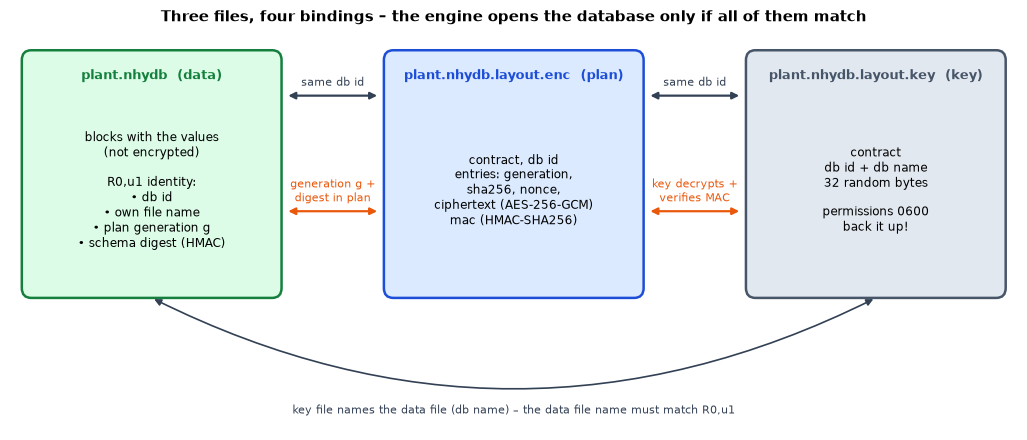

In [4]:
fig, ax = plt.subplots(figsize=(13, 5.2))
boxes = {
    "data": (0.0, 1.2, "B", "plant.nhydb  (data)",
             "blocks with the values\n(not encrypted)\n\nR0,u1 identity:\n• db id\n• own file name\n"
             "• plan generation g\n• schema digest (HMAC)"),
    "plan": (4.6, 1.2, "A", "plant.nhydb.layout.enc  (plan)",
             "contract, db id\nentries: generation,\nsha256, nonce,\nciphertext (AES-256-GCM)\n"
             "mac (HMAC-SHA256)"),
    "key": (9.2, 1.2, "C", "plant.nhydb.layout.key  (key)",
            "contract\ndb id + db name\n32 random bytes\n\npermissions 0600\nback it up!"),
}
for name, (x, y, layer, head, text) in boxes.items():
    ax.add_patch(FancyBboxPatch((x, y), 3.2, 2.9, boxstyle="round,pad=0.05,rounding_size=0.12",
                                facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.8))
    ax.text(x + 1.6, y + 2.6, head, ha="center", fontweight="bold", color=COLORS[layer], fontsize=9)
    ax.text(x + 1.6, y + 1.25, text, ha="center", va="center", fontsize=8.5)


def link(x1, x2, y, text, color):
    ax.annotate("", xy=(x2, y), xytext=(x1, y), arrowprops=dict(arrowstyle="<|-|>", color=color, lw=1.6))
    ax.text((x1 + x2) / 2, y + 0.12, text, ha="center", fontsize=8, color=color)


link(3.3, 4.5, 3.6, "same db id", "#334155")
link(3.3, 4.5, 2.2, "generation g +\ndigest in plan", COLORS["attention"])
link(7.9, 9.1, 3.6, "same db id", "#334155")
link(7.9, 9.1, 2.2, "key decrypts +\nverifies MAC", COLORS["attention"])
ax.annotate("", xy=(10.8, 1.15), xytext=(1.6, 1.15),
            arrowprops=dict(arrowstyle="<|-|>", color="#334155", lw=1.2, connectionstyle="arc3,rad=0.25"))
ax.text(6.2, -0.25, "key file names the data file (db name) – the data file name must match R0,u1",
        ha="center", fontsize=8, color="#334155")
ax.set_xlim(-0.2, 12.6)
ax.set_ylim(-0.45, 4.4)
ax.axis("off")
ax.set_title("Three files, four bindings – the engine opens the database only if all of them match")
plt.show()

## 3 · Ansicht 1: die verschlüsselte Plandatei

**Frage:** Was sieht jemand, der nur die Plandatei hat?

▶ **Ausprobieren:** die echte Datei, lange Felder gekürzt.

In [5]:
def shorten(value, n=44):
    s = str(value)
    return s if len(s) <= n else s[:n] + f"…  ({len(s)} characters)"


view1 = {
    "contract": plan["contract"],
    "db_id": plan["db_id"],
    "entries": [{k: shorten(v) for k, v in e.items()} for e in plan["entries"]],
    "mac": shorten(plan["mac"]),
}
print(json.dumps(view1, indent=2, ensure_ascii=False))

raw_plan = open(LIVE + ".layout.enc", "rb").read()
secrets_in_plan = {word: word.encode() in raw_plan for word in ("readings", "sensor", "temp_c", "grid", "x + 1")}
print("\nschema words visible in the plan file:", secrets_in_plan)
assert not any(secrets_in_plan.values())

{
  "contract": "NHYDB027_EXTERNAL_LAYOUT_V1",
  "db_id": "543b6b29-d264-45e5-92ac-590e9385c384",
  "entries": [
    {
      "ciphertext": "zfN29oh4P7Gar15N97cUmSuZNqdJANTtcfnrGfdoxB9s…  (180 characters)",
      "generation": "0",
      "nonce": "5q0fEkA7j11ieML9",
      "sha256": "61a8d6fec18577ecc53b90e78c25f8fe394de99be76b…  (64 characters)"
    },
    {
      "ciphertext": "YJCf8cy2NVywI65GkZSDQCWtiamesDBnL9rWuyy8OSlh…  (2108 characters)",
      "generation": "1",
      "nonce": "UPzX015ipWEQ8U+Z",
      "sha256": "5d2f4c6ce21b8f15e410f679333730a17f8f9f3131f1…  (64 characters)"
    }
  ],
  "mac": "0b654786378330e6e47d87b7f4c2eb53ace00efea08b…  (64 characters)"
}

schema words visible in the plan file: {'readings': False, 'sensor': False, 'temp_c': False, 'grid': False, 'x + 1': False}


**Was ist passiert?** Die Plandatei ist ein kleiner JSON-Umschlag. Ihre *Struktur* ist lesbar –
Vertrag, Datenbank-ID, Generationen, Nonces, ein MAC –, aber das Schema selbst ist ein
Base64-kodierter **Geheimtext**. Kein einziger Layoutname, Feldname oder keine einzige Formel
taucht in der Datei auf.

## 4 · Ansicht 2: die autorisierte Ansicht

**Frage:** Was enthält der Plan?

Mit dem Schlüssel entschlüsselt die Engine den Plan beim Öffnen der Datenbank. Das Schema steht
dann über die normale API zur Verfügung – das ist die **autorisierte Ansicht**. (Es gibt bewusst
keine API, die den entschlüsselten Plan auf die Platte schreibt; die Ansicht unten wird aus
`realms`, `stats()`, `index_defs`, `math_layouts` und `describe_math` zusammengesetzt.)

In [6]:
def authorized_view(path):
    lines = []
    with nhydb.open(path) as db:
        st = db.stats()
        math_realms = {e["physical_start"]: lid for lid in db.math_layouts
                       for e in db.describe_math(lid)["realm_extents"]}
        for rid, realm in sorted(db.realms.items()):
            owner = f"  (owned by MATH layout {math_realms[rid]})" if rid in math_realms else ""
            lines.append(f"realm {rid} '{realm['name']}'{owner}")
            for shape in (s for s in st["shapes"] if s["realm_id"] == rid):
                lines.append(f"├─ shape {shape['shape_id']} '{shape['name']}' ({shape['field_count']} fields)")
            for lay in (l for l in st["layouts"] if l["realm_id"] == rid):
                fields = ", ".join(f"v{f['v']} {f['name']}:{f['type']}" for f in lay["base"])
                lines.append(f"├─ layout {lay['layout_id']} '{lay['name']}' {lay['kind']}  record=u, field=v")
                lines.append(f"│    fields: {fields}")
            for idx in (i for i in db.index_defs.values() if i.realm_id == rid):
                lines.append(f"└─ index {idx.index_id} '{idx.name}' {idx.kind} on v{idx.v}")
        for lid in db.math_layouts:
            m = db.describe_math(lid)
            mp = m["mapping"]
            lines.append(f"MATH layout {lid} '{m['name']}': inputs {tuple(mp['parameters'])} → "
                         f"u = {mp['u']}, V = {mp['V']}, side = {'NR' if mp['side'] == 1 else mp['side']}")
            lines.append(f"   payload {m['payload_type']}, realm map {m['realm_extents']}, frozen = {m['frozen']}")
    return "\n".join(lines)


VIEW2 = authorized_view(LIVE)
print(VIEW2)

realm 1 'sensors'
├─ shape 1 'reading' (2 fields)
├─ layout 1 'readings' CLASSIC  record=u, field=v
│    fields: v1 sensor:utf8, v2 temp_c:f64
realm 2 'Realm 2'  (owned by MATH layout 2)
MATH layout 2 'grid': inputs ('x', 'y') → u = x + 1, V = y, side = NR
   payload utf8, realm map [{'logical_start': 1, 'logical_end': 1, 'physical_start': 2, 'physical_end': 2}], frozen = True


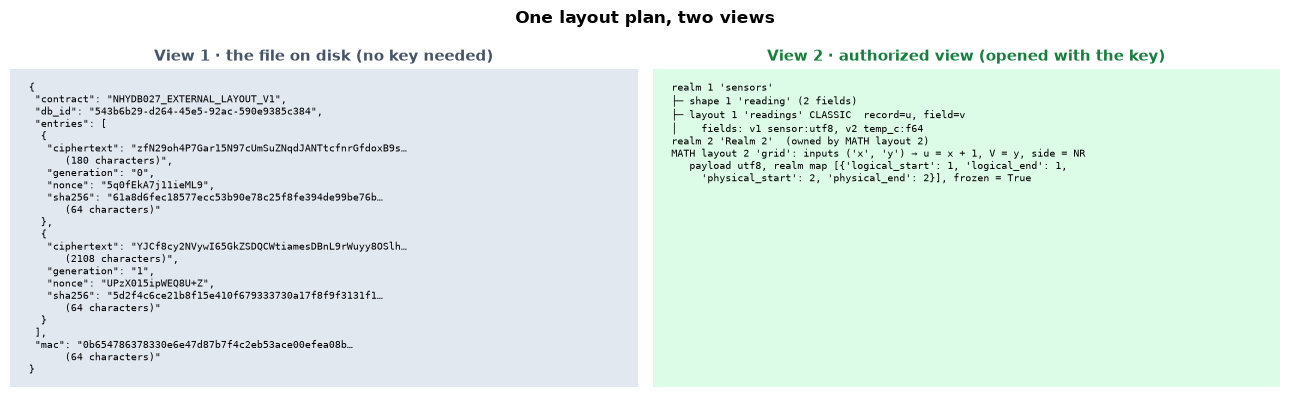

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.0))
import textwrap
enc_text = json.dumps(view1, indent=1, ensure_ascii=False).replace("  (", "\n      (")
view2_text = "\n".join(textwrap.fill(line, 78, subsequent_indent="     ") for line in VIEW2.splitlines())
for ax, title, text, layer in ((ax1, "View 1 · the file on disk (no key needed)", enc_text, "C"),
                               (ax2, "View 2 · authorized view (opened with the key)", view2_text, "B")):
    ax.add_patch(FancyBboxPatch((0, 0), 1, 1, boxstyle="round,pad=0.01,rounding_size=0.02",
                                facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.5,
                                transform=ax.transAxes))
    ax.text(0.03, 0.96, text, va="top", ha="left", family="monospace", fontsize=7, transform=ax.transAxes)
    ax.set_title(title, color=COLORS[layer])
    ax.axis("off")
fig.suptitle("One layout plan, two views", fontweight="bold")
plt.tight_layout()
plt.show()

## 5 · Jede Schemaänderung ist eine neue Plangeneration

**Frage:** Was passiert mit dem Plan, wenn sich das Schema ändert?

▶ **Ausprobieren:** Wir behalten eine Kopie der aktuellen Plandatei und fügen dann einen Index
hinzu. Der Commit versiegelt eine neue Generation, schreibt den Plan mit **[vorige, neue]**
Generation neu und vermerkt die neue Generation und den Schema-Digest in R0,u1.

In [8]:
OLD_PLAN = os.path.join(WORKDIR, "plan_before_index.enc")
shutil.copy2(LIVE + ".layout.enc", OLD_PLAN)


def generation_state(path):
    with nhydb.open(path) as db:
        cells = db.get_system_metadata()["cells"]
    entries = json.load(open(path + ".layout.enc"))["entries"]
    return {"R0,u1 generation": cells["5"], "R0,u1 digest": cells["6"][:12] + "…",
            "plan holds generations": [e["generation"] for e in entries]}


before = generation_state(LIVE)
with nhydb.open(LIVE) as db:
    db.create_index(1, 1, "by_sensor", "sensor")
    db.build_indexes(commit=True)
after = generation_state(LIVE)
assert after["R0,u1 generation"] == before["R0,u1 generation"] + 1
pd.DataFrame([before, after], index=["before the index", "after the index"])

,"R0,u1 generation","R0,u1 digest",plan holds generations
before the index,1,5d2f4c6ce21b…,"[0, 1]"
after the index,2,6601f7ee7802…,"[1, 2]"


**Was ist passiert?** Die Generation ist um eins gestiegen, und der Schema-Digest hat sich geändert.
Der Plan behält genau zwei Generationen, damit sich ein Absturz zwischen dem Schreiben des Plans
und dem Commit der Datendatei immer auflösen lässt (Technische Dokumentation, Abschnitt 8.5).

## 6 · Das Angriffslabor

**Frage:** Was passiert, wenn Dateien fehlen, vertauscht oder manipuliert sind?

Jedes Szenario arbeitet auf einer **frischen Kopie** der drei Dateien; die Originaldatenbank wird
nie angefasst. Eine zweite Datenbank mit **demselben Dateinamen** dient als „fremde“ Quelle für
vertauschte Dateien. In jedem Szenario versuchen wir, die Kopie zu öffnen und die bekannten Werte
zu lesen.

In [9]:
other_dir = os.path.join(WORKDIR, "other")
os.makedirs(other_dir, exist_ok=True)
OTHER = os.path.join(other_dir, "plant.nhydb")               # same name, different database
with nhydb.create(OTHER) as db:
    db.create_realm(1, "something else")


def flip_char(path, field):
    # change one character inside a JSON field of the plan file
    data = json.load(open(path))
    target = data["entries"][-1] if field == "ciphertext" else data
    s = target[field]
    target[field] = s[:10] + ("A" if s[10] != "A" else "B") + s[11:]
    json.dump(data, open(path, "w"))


def flip_data_byte(path):
    # change one byte of a stored value in the data file ('boiler' -> 'Boiler')
    raw = bytearray(open(path, "rb").read())
    pos = raw.index(b"boiler")
    raw[pos] ^= 0x20
    open(path, "wb").write(raw)


def rename_data(path):
    new = os.path.join(os.path.dirname(path), "renamed.nhydb")
    os.rename(path, new)
    return new, {"layout_path": path + ".layout.enc", "key_path": path + ".layout.key"}


SCENARIOS = [
    ("intact copy (control)",            lambda p: None),
    ("key file missing",                 lambda p: os.remove(p + ".layout.key")),
    ("plan file missing",                lambda p: os.remove(p + ".layout.enc")),
    ("one character of ciphertext",      lambda p: flip_char(p + ".layout.enc", "ciphertext")),
    ("one character of the MAC",         lambda p: flip_char(p + ".layout.enc", "mac")),
    ("key of another database",          lambda p: shutil.copy2(OTHER + ".layout.key", p + ".layout.key")),
    ("plan of another database",         lambda p: shutil.copy2(OTHER + ".layout.enc", p + ".layout.enc")),
    ("data file renamed",                rename_data),
    ("one byte of a value in the data",  flip_data_byte),
]

lab = []
for i, (name, attack) in enumerate(SCENARIOS):
    path = copy_db(LIVE, os.path.join(WORKDIR, f"lab_{i}"))
    changed = attack(path)
    options = {}
    if isinstance(changed, tuple):
        path, options = changed
    try:
        values = read_known_values(path, **options)
        lab.append({"scenario": name, "opened": True, "result": f"values read: {values == EXPECTED}"})
    except Exception as e:
        lab.append({"scenario": name, "opened": False, "result": short(e)})

lab = pd.DataFrame(lab).set_index("scenario")
assert lab["opened"].tolist() == [True] + [False] * 8
pd.set_option("display.max_colwidth", 110)
lab

,opened,result
scenario,,
intact copy (control),True,values read: True
key file missing,False,FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.key'
plan file missing,False,FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.enc'
one character of ciphertext,False,CorruptionError: Layout plan: integrity check failed
one character of the MAC,False,CorruptionError: Layout plan: integrity check failed
key of another database,False,CorruptionError: Wrong layout key file (database ID or name does not match)
plan of another database,False,CorruptionError: External layout plan does not belong to the database
data file renamed,False,"CorruptionError: DB file name 'renamed.nhydb' does not match the name 'plant.nhydb' bound in R0,u1: the da..."
one byte of a value in the data,False,CorruptionError: block 3: payload CRC mismatch


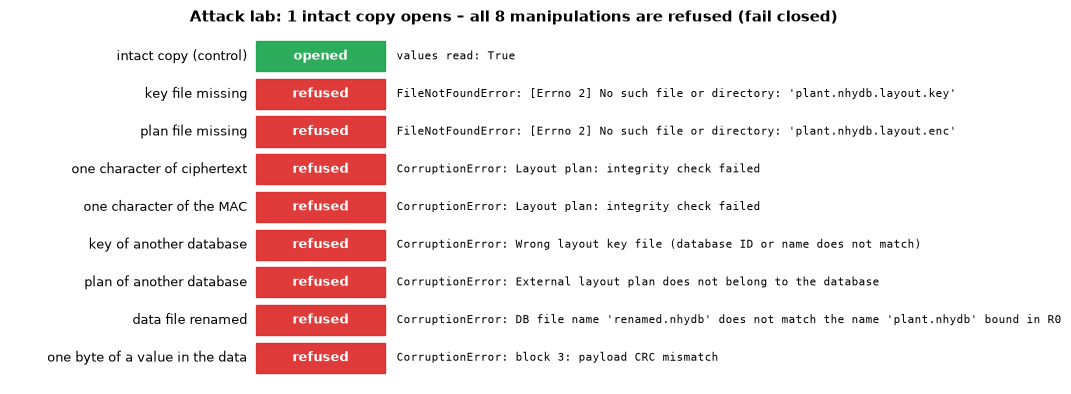

In [10]:
fig, ax = plt.subplots(figsize=(13, 4.6))
for i, (name, row) in enumerate(lab.iterrows()):
    y = len(lab) - 1 - i
    color = COLORS["ok"] if row["opened"] else COLORS["bad"]
    ax.add_patch(Rectangle((0, y - 0.4), 2.2, 0.8, color=color, alpha=0.9))
    ax.text(1.1, y, "opened" if row["opened"] else "refused", ha="center", va="center", color="white",
            fontweight="bold", fontsize=9)
    ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    ax.text(2.4, y, row["result"][:95], va="center", fontsize=8, family="monospace")
ax.set_xlim(-4.2, 13)
ax.set_ylim(-0.7, len(lab) - 0.3)
ax.axis("off")
ax.set_title("Attack lab: 1 intact copy opens – all 8 manipulations are refused (fail closed)")
plt.show()

**Was ist passiert? – fail closed**

* Fehlende Dateien: Die Engine kann gar nicht erst starten (`FileNotFoundError`).
* Ein geändertes Zeichen im Geheimtext oder im MAC: Die HMAC-Prüfung schlägt fehl, bevor
  irgendetwas entschlüsselt wird (`integrity check failed`).
* Dateien aus einer anderen Datenbank – selbst mit demselben Dateinamen – werden an der
  Datenbank-ID erkannt (`Wrong layout key file`, `does not belong to the database`).
* Eine umbenannte Datendatei passt nicht mehr zu dem in R0,u1 gespeicherten Namen.
* Ein einziges geändertes Byte eines gespeicherten Werts wird von der Blockprüfsumme (CRC) der
  Datendatei erkannt.

In jedem Fall **verweigert** die Engine das Öffnen, statt falsche oder unvollständige Daten zu
liefern. **Ah – die drei Dateien funktionieren nur als Satz, und nur unverändert.**

## 7 · Die Originale wiederherstellen – und alles funktioniert wieder

Das Angriffslabor hat nur Kopien angefasst. Um den Reparaturweg zu zeigen, beschädigen wir eine
„lebende“ Kopie, sehen sie scheitern, legen die exakten Originalbytes von Plan und Schlüssel
zurück (die Schlüsseldatei wieder mit den Rechten `0600` – sonst warnt NHyDB, dass andere sie
lesen können) und lesen dieselben Werte erneut.

In [11]:
work = copy_db(LIVE, os.path.join(WORKDIR, "restore_demo"))
saved = {s: open(work + s, "rb").read() for s in (".layout.enc", ".layout.key")}   # exact bytes

flip_char(work + ".layout.enc", "mac")
os.remove(work + ".layout.key")
try:
    read_known_values(work)
except (FileNotFoundError, nhydb.CorruptionError) as e:
    print("damaged copy →", short(e))

for suffix, content in saved.items():                                                # restore
    open(work + suffix, "wb").write(content)
os.chmod(work + ".layout.key", 0o600)                                                # key stays private
restored_values = read_known_values(work)
print("after restoring the original bytes:", restored_values)
assert restored_values == EXPECTED

damaged copy → FileNotFoundError: [Errno 2] No such file or directory: 'plant.nhydb.layout.key'
after restoring the original bytes: ('boiler', 40.25, 'calibration 2026')


## 8 · Den Schlüssel woanders aufbewahren

Die Schlüsseldatei muss nicht neben den Daten liegen. Gib beim Anlegen der Datenbank und bei jedem
Öffnen `key_path` an (oder trage den Pfad in die Konfigurationsdatei ein, Cookbook-Abschnitt 19).
Wer nur den Datenordner kopiert, kann die Datenbank nicht öffnen.

In [12]:
data_dir = os.path.join(WORKDIR, "data_only")
key_dir = os.path.join(WORKDIR, "key_vault")
os.makedirs(data_dir)
os.makedirs(key_dir)
SECURE = os.path.join(data_dir, "secure.nhydb")
KEY = os.path.join(key_dir, "secure.nhydb.layout.key")

with nhydb.create(SECURE, key_path=KEY) as db:
    db.create_realm(1, "r")
    db.put_cell(1, 1, 1, "inside", type="utf8")
print("data folder:", sorted(os.listdir(data_dir)))
print("key folder: ", sorted(os.listdir(key_dir)))
print("key file permissions:", oct(os.stat(KEY).st_mode & 0o777) if os.name == "posix" else "(Windows ACL)")

try:
    nhydb.open(SECURE)
except FileNotFoundError as e:
    print("without key_path →", type(e).__name__)
with nhydb.open(SECURE, key_path=KEY) as db:
    assert db.get_value(1, 1, 1) == "inside"
    print("with key_path    → opened:", db.get_value(1, 1, 1))

data folder: ['secure.nhydb', 'secure.nhydb.layout.enc', 'secure.nhydb.lock']
key folder:  ['secure.nhydb.layout.key']
key file permissions: 0o600
without key_path → FileNotFoundError
with key_path    → opened: inside


## 9 · Die ehrlichen Grenzen

Beim Planschutz geht es um das **Schema** und darum, inkonsistente Dateien **abzuweisen**. Er macht
die gespeicherten Werte nicht geheim: Die Datendatei wird im Klartext geschrieben.

In [13]:
raw_data = open(LIVE, "rb").read()
visible = {word: word.encode() in raw_data for word in ("boiler", "pump", "calibration 2026")}
hidden = {word: word.encode() in raw_data for word in ("readings", "temp_c", "x + 1")}
print("values visible in the data file:     ", visible)
print("schema names visible in the data file:", hidden)
assert all(visible.values()) and not any(hidden.values())

values visible in the data file:      {'boiler': True, 'pump': True, 'calibration 2026': True}
schema names visible in the data file: {'readings': False, 'temp_c': False, 'x + 1': False}


**Was ist passiert?** Werte wie `boiler` oder `calibration 2026` lassen sich mit einer einfachen
Bytesuche in `plant.nhydb` finden; Namen von Layouts, Feldern und Formeln nicht. Ohne den Plan kann
niemand zuverlässig sagen, welche Bytes zu welchem Datensatz, Feld oder welcher Formel gehören –
aber das ist **keine** Verschlüsselung der Daten. Schütze Datendateien mit Dateisystemrechten oder
Festplattenverschlüsselung, und bewahre eine Sicherung der Schlüsseldatei auf: Ein verlorener
Schlüssel lässt sich nicht wiederherstellen.

| Was der Planschutz leistet | Was er nicht leistet |
|---|---|
| hält das Schema (Layouts, Felder, MATH-Formeln, Indizes) verschlüsselt | die gespeicherten Werte verschlüsseln |
| bindet Daten, Plan und Schlüssel aneinander (ID, Name, Generation, Digest) | Backups ersetzen – ein verlorener Schlüssel ist verloren |
| verweigert das Öffnen bei jeder fehlenden oder manipulierten Datei | vor jemandem schützen, der alle drei Dateien hat |

## Jetzt du

**Aufgabe:** Wir haben eine Kopie der Plandatei von **vor** dem Hinzufügen des Index behalten
(Abschnitt 5). Was passiert, wenn durch eine Verwechslung beim Backup dieser ältere Plan neben der
aktuellen Datendatei landet? Erst vorhersagen.

In [14]:
# Solution: the data file says "generation g+1"; the old plan only knows generations up to g → refused.
mixup = copy_db(LIVE, os.path.join(WORKDIR, "mixup"))
shutil.copy2(OLD_PLAN, mixup + ".layout.enc")
try:
    read_known_values(mixup)
    outcome = "opened"
except nhydb.CorruptionError as e:
    outcome = short(e)
print("old plan + new data →", outcome)
assert outcome.startswith("CorruptionError")

old plan + new data → CorruptionError: no layout plan matching R0,u1 generation and hash


## ⏩ Vertiefung: wie die Plandatei aufgebaut ist

Aus der technischen Dokumentation (Abschnitt 8.3) – für alle, die die Details wissen wollen:

* **Schlüsseldatei:** JSON `{"contract": "NHYDB027_KEY_V1", "db_id", "db_name", "key_b64"}` mit
  32 Zufallsbytes, exklusiv angelegt mit den Rechten `0600`.
* **Plandatei:** JSON `{"contract": "NHYDB027_EXTERNAL_LAYOUT_V1", "db_id", "entries": [1..2], "mac"}`;
  `mac = HMAC-SHA256(SHA256("NHYDB027-LAYOUT-MAC:" ‖ key), envelope without mac)`.
* **Eintrag:** `{"generation", "sha256", "nonce", "ciphertext"}`, AES-256-GCM mit einer 12 Byte
  langen zufälligen Nonce und den zusätzlich authentifizierten Daten `"NHYDB027:{db_id}:{generation}:{sha256}"`.
  Das Feld `sha256` enthält den Schema-Digest `HMAC-SHA256(SHA256("NHYDB027-SCHEMA-DIGEST:" ‖ key), schema)`
  – ein erratenes Schema lässt sich ohne den Schlüssel nicht bestätigen.
* **Öffnen:** Superblöcke lesen → Blockverzeichnis lesen und die übrigen Blöcke scannen →
  Dateinamen gegen R0,u1 prüfen → Schlüssel laden → MAC prüfen → den Eintrag mit Generation und
  Digest aus R0 finden → entschlüsseln → Digest und Vertrag prüfen → erst dann einen nicht
  committeten Rest abschneiden. Jeder Fehler vor dem letzten Schritt lässt die Datei unverändert.

## Zusammenfassung

* Daten (`.nhydb`), Plan (`.layout.enc`) und Schlüssel (`.layout.key`) bilden einen Satz, gebunden durch ID, Name, Generation und Schema-Digest.
* Die Plandatei zeigt nur einen Umschlag; das Schema ist AES-256-GCM-Geheimtext mit einem HMAC-SHA256-MAC.
* Die autorisierte Ansicht – das vollständige Schema – existiert nur in einer geöffneten Datenbank.
* Jede Schemaänderung versiegelt eine neue Generation; der Plan behält die aktuelle und die vorige.
* Alle acht Manipulationen wurden abgewiesen; die Datendatei selbst ist nicht verschlüsselt – schütze sie wie jede andere Datei.

## Wie es weitergeht

* [11 · Was liegt eigentlich auf der Platte?](11_what_lives_on_disk_v1.ipynb) – Backups und die Commit-Grenze.
* [14 · Eine kleine echte Anwendung bauen](14_complete_application_v1.ipynb) – alles zusammen.

**Cookbook-Abschnitte:** 21 (Datenbankdateien, Backup), 23 (Systembereich R0,u1), 19 (Konfiguration: key_path) im [NHyDB Python Cookbook](https://github.com/nhydb-run4/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [15]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
